# 현실의 데이터 21: 전력 수요 예측

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/21_electricity.ipynb)

**분야**: 도시 · 공간 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 에너지 · 전력 · 시계열 예측 · 스마트 그리드

> 다음 한 시간, 이 집은 전기를 얼마나 쓸까?

**데이터**: UCI Individual Household Electric Power Consumption (약 20MB (압축)). Hebrail & Berard (2012). 프랑스 한 가정의 2006-12 ~ 2010-11 1분 간격 전력 사용량 약 207만 줄 (전체 · 부엌 · 세탁실 · 냉난방 계량기).

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 한 시간 |
| ② 입력 X | 지난 몇 시간 · 어제 같은 시각 · 지난주 같은 시각 · 시각 · 요일 |
| ③ 출력 y | 다음 한 시간 평균 사용량 (kW) |
| ④ 평가지표 | MAE · RMSE |
| ⑤ 기준선 | 지난 한 시간 그대로 · 어제 같은 시각 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [UCI 데이터 설명 (Hebrail & Berard, 2012)](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

1분 간격 207만 줄. 읽는 데 30초쯤 걸린다. 빈칸은 '?' 로 적혀 있다 (1주 3차시 '숫자인 척하는 결측치' 와 비슷).

In [2]:
URL = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"
with zipfile.ZipFile(download(URL, "data/household_power.zip")) as z:
    raw = pd.read_csv(z.open("household_power_consumption.txt"), sep=";", na_values="?", low_memory=False)
raw["time"] = pd.to_datetime(raw["Date"] + " " + raw["Time"], format="%d/%m/%Y %H:%M:%S")
raw = raw.set_index("time").drop(columns=["Date", "Time"])
print(raw.shape, raw.index.min(), "~", raw.index.max())
print(f"missing minutes: {raw['Global_active_power'].isna().mean():.2%}")
raw.sample(5, random_state=0)

(2075259, 7) 2006-12-16 17:24:00 ~ 2010-11-26 21:02:00
missing minutes: 1.25%


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
time,,,,,,,
2008-03-30 21:12:00,3.112,0.000,236.63,13.2,1.0,0.0,17.0
2010-04-29 09:29:00,2.210,0.246,239.55,9.2,0.0,1.0,18.0
2009-07-31 00:05:00,0.666,0.078,242.29,2.8,0.0,0.0,0.0
2010-06-02 09:08:00,1.292,0.058,238.26,5.4,0.0,1.0,18.0
2007-01-25 21:13:00,1.964,0.076,242.06,8.2,0.0,0.0,18.0


## 열어 보기: 한 시간 단위로

1분 값을 한 시간 평균으로 모은다 (kW). 하루 중 언제, 1년 중 언제 많이 쓸까?

(34589, 1)


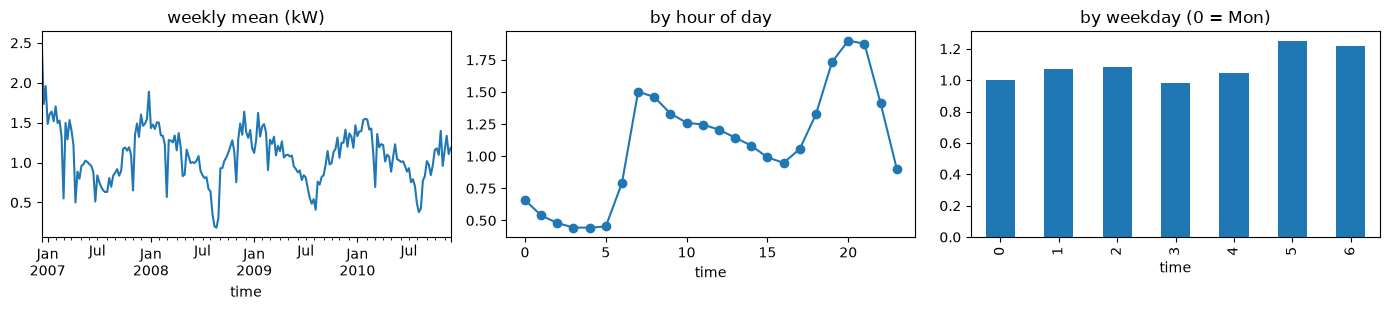

In [3]:
hourly = raw["Global_active_power"].resample("h").mean().to_frame("kw")
print(hourly.shape)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.2))
hourly["kw"].resample("W").mean().plot(ax=axs[0], title="weekly mean (kW)")
hourly.groupby(hourly.index.hour)["kw"].mean().plot(ax=axs[1], marker="o", title="by hour of day")
hourly.groupby(hourly.index.dayofweek)["kw"].mean().plot(kind="bar", ax=axs[2], title="by weekday (0 = Mon)")
plt.tight_layout(); plt.show()

## 문제 하나 골라 보기: 지금까지 → 다음 한 시간

**시간 순서**: 2009년까지 학습, 2010년 시험. 기준선 3가지와 모델 비교.

In [4]:
from sklearn.ensemble import HistGradientBoostingRegressor

h = hourly.copy()
for k in (1, 2, 3, 24, 168):
    h[f"lag{k}"] = h["kw"].shift(k)
h["yday"] = h["kw"].shift(23)                     # the target hour, one day earlier
h["hour"], h["dow"] = h.index.hour, h.index.dayofweek
h["target"] = h["kw"].shift(-1)
h = h.dropna()
feats = ["kw", "lag1", "lag2", "lag3", "lag24", "lag168", "hour", "dow"]
tr, te = h[h.index.year < 2010], h[h.index.year == 2010]
m = HistGradientBoostingRegressor(random_state=0).fit(tr[feats], tr["target"])
y = te["target"].values
for name, pred in [("last hour", te["kw"].values), ("same hour yesterday", te["yday"].values),
                   ("gradient boosting", m.predict(te[feats]))]:
    err = pred - y
    print(f"{name:20s} MAE {np.mean(np.abs(err)):.3f} kW   RMSE {np.sqrt(np.mean(err ** 2)):.3f} kW")

last hour            MAE 0.408 kW   RMSE 0.619 kW
same hour yesterday  MAE 0.556 kW   RMSE 0.821 kW
gradient boosting    MAE 0.348 kW   RMSE 0.499 kW


**관찰**: '지난 한 시간 그대로' 가 꽤 강한 기준선이다. 모델은 시각 · 요일 패턴을 더해 조금 더 낫다. 한 집의 사용량은 갑자기 켜는 기기 (오븐, 세탁기) 때문에 들쭉날쭉해서 크게 줄이기 어렵다. 수많은 집을 합친 전력망 전체 수요는 훨씬 잘 맞는다.

## 다른 문제로 바꿔 보기

- **이상 탐지**: 평소와 다르게 많이 쓰는 시간 (전기 새는 곳, 고장) 찾기.
- **기기 분리 (NILM)**: 전체 사용량만 보고 부엌 · 세탁실 · 냉난방이 각각 얼마 썼는지 맞히기. 이 데이터에 정답 계량기 (Sub_metering_1~3) 가 있다.

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |